<a href="https://colab.research.google.com/github/RoihansLab/Data-Mining-Project/blob/main/youtube_comment_sentiment/Classification/finetune_transformer_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Percobaan: Fine-tuning Transformer di Google Colab**

Notebook ini **terpisah** dari notebook utama (`classification_modeling.ipynb`). Tujuannya hanya membandingkan: apakah *fine-tuning* model Transformer dengan GPU Colab bisa mengalahkan model akhir (**e5-large + SVM linear**, macro-F1 sekitar 0,64)?

**Kenapa dipisah ke notebook sendiri?**
*Fine-tuning* XLM-RoBERTa-large (sekitar 560 juta parameter) butuh memori GPU yang besar. GPU laptop kami (NVIDIA RTX 4050, **6 GB**) tidak cukup untuk melatih model sebesar ini. Karena itu pelatihan dan pengujiannya dijalankan di **Google Colab** dengan meminjam GPU yang lebih kuat (**NVIDIA T4, 16 GB**). Notebook utama tetap bisa dijalankan di laptop, karena e5-large di sana hanya dipakai (tidak dilatih ulang). Hasil notebook ini dicatat di Bab 9.5 notebook utama sebagai pembanding.

**Supaya perbandingannya adil:**
- Memakai data dan label yang sama (`youtube_comments_label_final.csv`).
- Memakai **data uji yang sama persis** (3.927 komentar, dibagi 80:20, `random_state=42`, *stratified*).
- Data uji hanya dipakai **sekali di akhir**. Pemilihan epoch terbaik memakai **10% data latih** sebagai data validasi.

**Cara pakai:**
1. Pilih *Runtime → Change runtime type → T4 GPU*.
2. Dataset diambil otomatis dari GitHub, jadi tidak perlu upload file.
3. Jalankan semua sel (*Runtime → Run all*). Dengan `xlm-roberta-large` sekitar 30-40 menit (pelatihan saja sekitar 36 menit di GPU T4).

## **1. Import Library**

In [1]:
# Pasang library yang belum ada
!pip install -q Sastrawi transformers accelerate

In [2]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer

# Kunci semua sumber acak dengan angka 42
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "TIDAK ADA (pilih T4 GPU di Runtime)")

GPU: Tesla T4


## **2. Data dan Pembagian yang Sama dengan Notebook Utama**

Di notebook utama, 8 komentar dibuang karena menjadi kosong setelah *removing* dan *stopword* (Bab 6.3-6.4). Data diambil langsung dari **GitHub**, lalu aturan yang sama diulang **hanya untuk menentukan baris mana yang dibuang**, supaya pembagian data latih dan uji sama persis. Transformer sendiri membaca **teks komentar asli** (kolom `comment`), karena model ini memahami kalimat lengkap.

In [3]:
# Dataset diambil langsung dari GitHub (butuh internet)
url = "https://raw.githubusercontent.com/RoihansLab/Data-Mining-Project/main/datasets/youtube_comments_label_final.csv"

df = pd.read_csv(url)
df.head()

,video_title,comment,likes,author_id,bahasa,label,sumber_label
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,0,Indonesia,perlu ditinjau,claude
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,1,Indonesia,negatif,claude
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,2,Indonesia,negatif,manual
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,3,Indonesia,negatif,claude
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi meningk...,85,4,Indonesia,negatif,claude


In [4]:
# Ulangi aturan Bab 6.2-6.4 notebook utama, HANYA untuk menentukan komentar yang dibuang
# 1. Case folding dan removing
teks = df["comment"].str.lower()
teks = teks.str.replace(r"https?://\S+|www\.\S+", " ", regex=True)
teks = teks.str.replace(r"[^a-z\s]", " ", regex=True)

# 2. Stopword (kata negasi tetap disimpan)
negasi = {"tidak", "belum", "nggak", "not", "no", "nor", "never", "nothing", "none", "cannot"}
stopword_indonesia = set(StopWordRemoverFactory().get_stop_words())
stopword_inggris = set(ENGLISH_STOP_WORDS)
stopword = (stopword_indonesia | stopword_inggris) - negasi


def buang_stopword(teks):
    kata_tersisa = []
    for kata in teks.split():
        if kata not in stopword:
            kata_tersisa.append(kata)
    return " ".join(kata_tersisa)


teks = teks.apply(buang_stopword)

# 3. Buang komentar yang menjadi kosong
df = df[teks != ""].reset_index(drop=True)
print("Jumlah komentar:", len(df))

Jumlah komentar: 3927


In [5]:
# 1. Pembagian sama dengan notebook utama (80% latih, 20% uji)
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["label"])

# 2. 10% data latih dipakai sebagai validasi untuk memilih epoch terbaik
df_latih, df_val = train_test_split(df_train, test_size=0.1, random_state=42, stratify=df_train["label"])

print("Latih   :", len(df_latih))
print("Validasi:", len(df_val))
print("Uji     :", len(df_test))

Latih   : 2826
Validasi: 315
Uji     : 786


## **3. Tokenisasi**

`MODEL` bisa diganti. Pilihan yang cocok untuk komentar bahasa Indonesia + Inggris:

| Model | Ukuran | Catatan |
|---|---|---|
| `xlm-roberta-large` | 560 juta parameter | paling kuat, perlu GPU T4 (sekitar 30-40 menit) |
| `xlm-roberta-base` | 280 juta parameter | lebih cepat (sekitar 8-10 menit) |
| `microsoft/mdeberta-v3-base` | 280 juta parameter | alternatif, kadang tidak stabil |

Komentar dipotong maksimal **128 token** (cukup untuk sebagian besar komentar).

In [6]:
MODEL = "xlm-roberta-large"

# Label diubah menjadi angka, karena model hanya bisa membaca angka
label_ke_id = {"negatif": 0, "perlu ditinjau": 1, "positif": 2}
id_ke_label = {0: "negatif", 1: "perlu ditinjau", 2: "positif"}

tokenizer = AutoTokenizer.from_pretrained(MODEL)

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

In [7]:
class DataKomentar(torch.utils.data.Dataset):
    """Membungkus komentar dan label supaya bisa dibaca oleh Trainer."""

    def __init__(self, d):
        # Ubah komentar menjadi token (maksimal 128 token per komentar)
        self.enc = tokenizer(d["comment"].tolist(), truncation=True, max_length=128, padding="max_length")
        self.y = d["label"].map(label_ke_id).tolist()

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        item = {}
        for nama, isi in self.enc.items():
            item[nama] = torch.tensor(isi[i])
        item["labels"] = torch.tensor(self.y[i])
        return item

In [8]:
data_latih = DataKomentar(df_latih)
data_val = DataKomentar(df_val)
data_uji = DataKomentar(df_test)

## **4. Fine-tuning**

- **Bobot label** (`balanced`): label yang sedikit (positif dan negatif) diberi bobot lebih besar di *loss*, sama seperti `class_weight="balanced"` di Logistic Regression.
- Dilatih **5 epoch**. Setiap akhir epoch dinilai di data validasi, lalu **epoch dengan macro-F1 validasi tertinggi** yang dipakai.
- `fp16=True` supaya hemat memori dan lebih cepat di GPU T4.

In [9]:
# Bobot label "balanced": label yang sedikit diberi bobot lebih besar
bobot = compute_class_weight("balanced", classes=np.arange(3), y=data_latih.y)
bobot = torch.tensor(bobot, dtype=torch.float)


class TrainerBerbobot(Trainer):
    """Trainer biasa, tetapi loss-nya memakai bobot label."""

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        label = inputs.pop("labels")
        keluaran = model(**inputs)
        loss = torch.nn.functional.cross_entropy(keluaran.logits, label, weight=bobot.to(keluaran.logits.device))
        if return_outputs:
            return loss, keluaran
        return loss

In [10]:
def hitung_metrik(hasil):
    tebakan = hasil.predictions.argmax(axis=1)
    return {
        "macro_f1": f1_score(hasil.label_ids, tebakan, average="macro"),
        "akurasi": accuracy_score(hasil.label_ids, tebakan),
    }

In [11]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=3, id2label=id_ke_label, label2id=label_ke_id)

# 10% langkah awal: learning rate naik pelan-pelan (warmup)
total_langkah = int(np.ceil(len(data_latih) / 16) * 5)
pemanasan = int(0.1 * total_langkah)

pengaturan = TrainingArguments(
    output_dir = "hasil_finetune",
    learning_rate = 1e-5,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size = 32,
    num_train_epochs = 5,
    warmup_steps = pemanasan,
    weight_decay = 0.01,
    eval_strategy = "epoch",
    save_strategy = "epoch",
    load_best_model_at_end = True,
    metric_for_best_model = "macro_f1",
    save_total_limit = 1,
    fp16 = torch.cuda.is_available(),
    seed = 42,
    report_to = "none"
)

trainer = TrainerBerbobot(
    model = model,
    args = pengaturan,
    train_dataset = data_latih,
    eval_dataset = data_val,
    compute_metrics = hitung_metrik
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-large
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [12]:
trainer.train()

Epoch,Training Loss,Validation Loss,Macro F1,Akurasi
1,No log,1.019357,0.485772,0.514286
2,No log,0.977247,0.470009,0.549206
3,1.003841,0.795662,0.618247,0.653968
4,1.003841,0.744550,0.654901,0.695238
5,1.003841,0.752795,0.658845,0.698413


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=885, training_loss=0.8663735599841101, metrics={'train_runtime': 2179.2107, 'train_samples_per_second': 6.484, 'train_steps_per_second': 0.406, 'total_flos': 3292058664092160.0, 'train_loss': 0.8663735599841101, 'epoch': 5.0})

**Grafik: hasil validasi per epoch.** Setiap akhir epoch, model dinilai di data validasi. Grafik dibuat dari angka yang memang kita catat selama pelatihan:

- **Kiri: macro-F1 dan akurasi validasi.** Macro-F1 adalah metrik utama proyek ini dan dipakai untuk memilih epoch terbaik (garis putus-putus hijau).
- **Kanan: *validation loss*.** Makin kecil makin baik. Kalau *loss* mulai naik lagi padahal pelatihan berlanjut, model mulai **overfitting** (menghafal data latih).

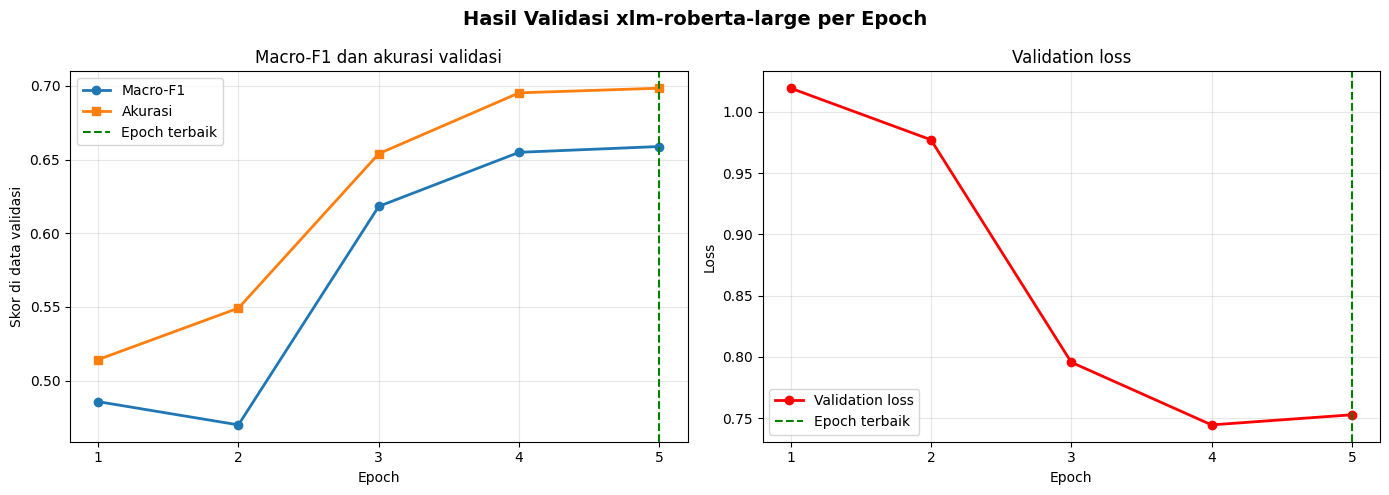

,epoch,eval_loss,eval_macro_f1,eval_akurasi
0,1.0,1.019,0.486,0.514
1,2.0,0.977,0.470,0.549
2,3.0,0.796,0.618,0.654
3,4.0,0.745,0.655,0.695
4,5.0,0.753,0.659,0.698


In [13]:
# 1. Ambil skor validasi setiap epoch dari catatan pelatihan
riwayat = []
for catatan in trainer.state.log_history:
    if "eval_macro_f1" in catatan:
        riwayat.append(catatan)
riwayat = pd.DataFrame(riwayat)

# 2. Epoch terbaik = epoch dengan macro-F1 validasi tertinggi (yang dipakai untuk data uji)
epoch_terbaik = riwayat.loc[riwayat["eval_macro_f1"].idxmax(), "epoch"]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 3. Kiri: macro-F1 dan akurasi validasi
ax[0].plot(riwayat["epoch"], riwayat["eval_macro_f1"], "o-", linewidth=2, label="Macro-F1")
ax[0].plot(riwayat["epoch"], riwayat["eval_akurasi"], "s-", linewidth=2, label="Akurasi")
ax[0].axvline(epoch_terbaik, color="green", linestyle="--", label="Epoch terbaik")
ax[0].set_xticks(riwayat["epoch"])
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Skor di data validasi")
ax[0].set_title("Macro-F1 dan akurasi validasi")
ax[0].legend()
ax[0].grid(alpha=0.3)

# 4. Kanan: validation loss
ax[1].plot(riwayat["epoch"], riwayat["eval_loss"], "o-", color="red", linewidth=2, label="Validation loss")
ax[1].axvline(epoch_terbaik, color="green", linestyle="--", label="Epoch terbaik")
ax[1].set_xticks(riwayat["epoch"])
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Loss")
ax[1].set_title("Validation loss")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.suptitle("Hasil Validasi " + MODEL + " per Epoch", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

riwayat[["epoch", "eval_loss", "eval_macro_f1", "eval_akurasi"]].round(3)

## **5. Evaluasi di Data Uji (sekali di akhir)**

Bandingkan dengan model akhir di notebook utama: **e5-large + SVM linear, macro-F1 sekitar 0,64 dan akurasi sekitar 0,72**.

In [14]:
# 1. Tebak data uji
hasil = trainer.predict(data_uji)
tebakan = hasil.predictions.argmax(axis=1)

# 2. Ubah angka kembali menjadi nama label
y_uji = df_test["label"].to_numpy()
y_pred = pd.Series(tebakan).map(id_ke_label).to_numpy()

print("Model:", MODEL)
print("Macro-F1:", round(f1_score(y_uji, y_pred, average="macro"), 3))
print("Akurasi :", round(accuracy_score(y_uji, y_pred), 3))

Model: xlm-roberta-large
Macro-F1: 0.657
Akurasi : 0.7


**Sel ini:** menampilkan skor per label dan confusion matrix XLM-RoBERTa di data uji.

**Cara membaca confusion matrix:** baris adalah **label asli**, kolom adalah **tebakan model**. Kotak di diagonal adalah tebakan yang **benar**. Kalau satu kolom (misalnya "positif") jauh lebih gelap daripada baris yang sama, berarti model **terlalu sering menebak label itu**.

In [15]:
print(classification_report(y_uji, y_pred, digits=3))

                precision    recall  f1-score   support

       negatif      0.612     0.697     0.652       188
perlu ditinjau      0.883     0.711     0.788       467
       positif      0.444     0.664     0.532       131

      accuracy                          0.700       786
     macro avg      0.646     0.691     0.657       786
  weighted avg      0.745     0.700     0.713       786



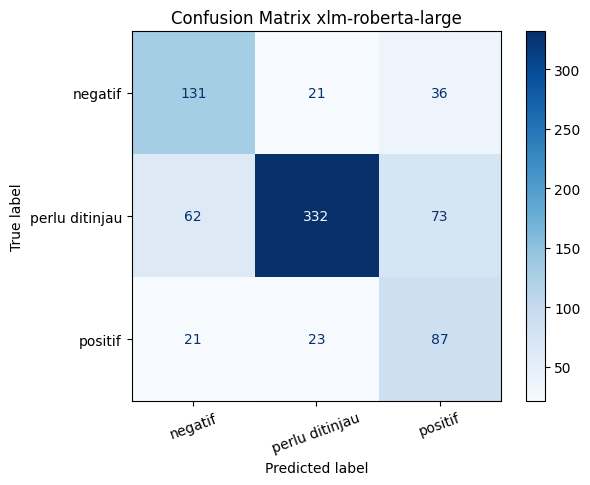

In [16]:
ConfusionMatrixDisplay.from_predictions(y_uji, y_pred, cmap="Blues", xticks_rotation=20)
plt.title("Confusion Matrix " + MODEL)
plt.show()

**Hasil (dijalankan di Google Colab, GPU T4, run terakhir):** pelatihan 5 epoch selesai dalam sekitar 36 menit.

| Epoch | Validation loss | Macro-F1 validasi | Akurasi validasi |
|---|---|---|---|
| 1 | 1,019 | 0,486 | 0,514 |
| 2 | 0,977 | 0,470 | 0,549 |
| 3 | 0,796 | 0,618 | 0,654 |
| 4 | **0,745** | 0,655 | 0,695 |
| 5 | 0,753 | **0,659** | **0,698** |

Pada grafik per epoch, macro-F1 naik tajam dari epoch 2 ke epoch 3 (0,470 → 0,618), lalu terus naik sampai **epoch 5** (0,659). Di grafik kanan, *validation loss* paling rendah di epoch 4 lalu sedikit naik di epoch 5: tanda awal **overfitting**, walaupun macro-F1 masih naik sedikit.

Epoch terbaik (epoch 5, macro-F1 validasi tertinggi) yang dipakai untuk data uji:

| Label | Precision | Recall | F1 |
|---|---|---|---|
| negatif | 0,612 | 0,697 | 0,652 |
| perlu ditinjau | 0,883 | 0,711 | 0,788 |
| positif | 0,444 | 0,664 | 0,532 |
| **Macro-F1 / akurasi** | | | **0,657 / 0,700** |

**Hasil tidak stabil antar-run.** Notebook ini sudah dijalankan dua kali dengan kode dan *seed* yang sama:

| Run | Epoch terbaik | Macro-F1 validasi | Macro-F1 uji | Akurasi uji |
|---|---|---|---|---|
| Run sebelumnya | 4 | 0,676 | 0,623 | 0,659 |
| **Run terakhir** | 5 | 0,659 | **0,657** | **0,700** |

- Skor uji XLM-RoBERTa-large berubah sekitar **0,03** hanya karena dijalankan ulang, walaupun *seed* dikunci 42. Penyebabnya, perhitungan GPU saat pelatihan tidak selalu deterministik. Sebaliknya, model akhir (e5-large + SVM linear) memberi hasil yang sama setiap dijalankan, karena e5-large hanya dipakai dan tidak dilatih ulang.
- Pada run terakhir, XLM-RoBERTa-large **sedikit di atas** model akhir (macro-F1 0,657 vs 0,639), tetapi pada run sebelumnya **di bawahnya** (0,623). Selisih keduanya masih di dalam rentang bootstrap model akhir (0,601-0,676), jadi XLM-RoBERTa-large **setara**, bukan jelas lebih baik.
- Model **masih terlalu sering menebak positif** (recall positif 0,664 tetapi precision hanya 0,444), sama seperti pada run sebelumnya.
- Skor lintas video (video baru) tidak dihitung, karena setiap pelatihan butuh sekitar 36 menit di GPU.
- Kesimpulan: model yang jauh lebih besar (sekitar 560 juta parameter) **tidak memberi keunggulan yang pasti**, karena data latih terbatas (2.826 komentar) dan hasilnya tidak stabil. Batas utamanya ada pada jumlah data dan kualitas label.

**Cara membaca hasil:**
- Jika macro-F1 **jauh lebih tinggi dari sekitar 0,64** (selisih lebih dari sekitar 0,03) dan hasilnya stabil saat dijalankan ulang, fine-tuning Transformer lebih baik untuk data ini.
- Jika **setara atau lebih rendah**, berarti batas utamanya ada pada jumlah data dan kualitas label, bukan pada kekuatan model.
- Selisih kecil (kurang dari sekitar 0,03) belum tentu berarti, karena masih di dalam variasi acak data uji (rentang bootstrap model akhir sekitar 0,60-0,68).
- Hasil fine-tuning bisa sedikit berbeda setiap dijalankan, walaupun *seed* sudah dikunci 42, karena perhitungan GPU tidak selalu deterministik.